# End-to-End Collections Investigation

**Purpose.** Reconstruct the supplied collection evidence, challenge the reported +11% claim, inspect operational drivers without confusing correlation with causation, and state what is needed before releasing ₹10 Cr.

**Evidence boundary.** The source README labels the package synthetic (seed 42). Events cover 1 January–8 August 2026, not twelve complete months. Gross successful payments are not net settled recovery. No historical exposure ledger, original KPI formula, payment-to-touch link or fully loaded cost ledger was supplied. This notebook intentionally reports unsupported metrics as unavailable.

Run the full build first from the repository root:

```bash
python scripts/run_pipeline.py
```

**Claim verdict: INCONCLUSIVE.** The available cash series does not verify an 11% recovery-rate improvement.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data" / "raw").exists():
    ROOT = ROOT.parent
RAW, PROC, GOLD, REPORTS = [ROOT / p for p in ["data/raw", "data/processed", "data/golden", "reports"]]
summary = json.loads((PROC / "pipeline_summary.json").read_text(encoding="utf-8"))
print("Project root:", ROOT)
print("Dataset:", summary.get("dataset", summary.get("dataset_label")))
print("Run ID:", summary.get("run_id", "not recorded"))

Project root: /mnt/data/collections-intelligence
Dataset: SYNTHETIC CHALLENGE DATA (seed 42)
Run ID: 20261030T094553Z


## 1. Source scope and completeness

The first question is whether the data actually covers the promised period. A complete-looking monthly chart is misleading if the input only has a partial period or one subsystem starts later than another.

In [2]:
inventory = pd.read_csv(PROC / "data_inventory_full.csv")
display(inventory[["source", "rows", "columns", "null_cells_pct", "full_row_duplicates"]].sort_values("source"))
print("Raw source rows:", int(inventory.rows.sum()))

,source,rows,columns,null_cells_pct,full_row_duplicates
0,account_status_history.csv,60000,8,0.0000,0
1,accounts.csv,30000,11,0.1379,0
2,agent_sessions.csv,15000,7,0.0000,0
3,agents.csv,30000,8,0.0000,0
4,borrowers.csv,30600,8,0.6164,600
5,call_attempts.csv,120000,9,0.2222,0
6,call_dispositions.csv,35000,8,0.0000,0
7,calls.csv,91350,11,0.1818,1271
8,campaigns.csv,120,7,0.0000,0
9,complaints.csv,8000,9,0.0000,0


Raw source rows: 639328


## 2. Payment integrity: duplicates, conflicts and cash status

Only exact full-row duplicates are removed. A repeated payment ID with different payloads is quarantined in full. A repeated payment reference is not treated as a global deduplication key. Successful events, reversals, failed events and pending events remain distinct.

In [3]:
payments = pd.read_csv(GOLD / "golden_payments.csv", low_memory=False)
status_check = payments.groupby("payment_status_norm").agg(
    rows=("payment_id", "size"), amount=("amount", "sum"),
    gross_success_amount=("gross_success_amount", "sum"), reversal_amount=("reversal_amount", "sum")
).reset_index()
display(status_check)
print(f"Golden payment rows: {len(payments):,}")
print(f"Successful events: {int((payments.payment_status_norm == 'SUCCESS').sum()):,}")
print(f"Gross successful cash: ₹{payments.gross_success_amount.sum():,.2f}")
print(f"Reversals reported separately: ₹{payments.reversal_amount.sum():,.2f}")
qpay = pd.read_csv(ROOT / "data/quarantine/payment_id_conflicts.csv", low_memory=False)
qcall = pd.read_csv(ROOT / "data/quarantine/event_id_conflicts.csv", low_memory=False)
print("Payment conflicts:", qpay.payment_id.nunique(), "IDs /", len(qpay), "rows")
print("Call conflicts:", qcall.loc[qcall.source_table.eq('calls'), 'call_id'].nunique(), "IDs /", int(qcall.source_table.eq('calls').sum()), "rows")

,payment_status_norm,rows,amount,gross_success_amount,reversal_amount
0,FAILED,3676,2.783918e+08,0.000000e+00,0.00
1,PENDING,2534,1.900810e+08,0.000000e+00,0.00
2,REVERSED,1253,9.465865e+07,0.000000e+00,94658651.01
3,SUCCESS,17523,1.314693e+09,1.314693e+09,0.00


Golden payment rows: 24,986
Successful events: 17,523
Gross successful cash: ₹1,314,693,465.14
Reversals reported separately: ₹94,658,651.01
Payment conflicts: 14 IDs / 28 rows
Call conflicts: 79 IDs / 158 rows


## 3. What happened to cash?

The monthly series answers only the cash-event question. It does not establish whether the eligible portfolio became more collectible because the outstanding exposure denominator is missing.

Jan to Jul gross cash change: +0.0040%
Feb to Mar gross cash change: +10.96%
Mean arithmetic MoM change Feb-Jul: +0.29%


,month,gross_cash_cr,gross_cash_mom_pct,successful_payment_events,reversal_events,complete_month
0,2026-01,18.722913,NaN,2464,174,True
1,2026-02,17.000529,-9.199335,2266,140,True
2,2026-03,18.863442,10.957970,2521,185,True
3,2026-04,17.504716,-7.202962,2405,177,True
4,2026-05,18.416507,5.208835,2448,160,True
5,2026-06,17.526600,-4.832116,2363,173,True
6,2026-07,18.723669,6.830013,2440,199,True
7,2026-08,4.710970,NaN,616,45,False


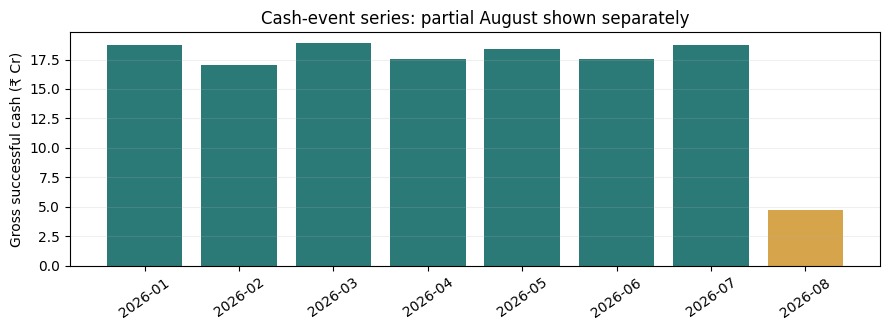

In [4]:
monthly = pd.read_csv(GOLD / "monthly_cash_metrics.csv").sort_values("month")
monthly["gross_cash_cr"] = monthly.gross_successful_collections / 1e7
monthly["mom_pct"] = monthly.gross_cash_mom_pct

def cr(month):
    return float(monthly.loc[monthly.month.eq(month), "gross_successful_collections"].iloc[0])
jan_jul = (cr("2026-07") / cr("2026-01") - 1) * 100
feb_mar = (cr("2026-03") / cr("2026-02") - 1) * 100
complete = monthly[monthly.complete_month.astype(bool)]
print(f"Jan to Jul gross cash change: {jan_jul:+.4f}%")
print(f"Feb to Mar gross cash change: {feb_mar:+.2f}%")
print(f"Mean arithmetic MoM change Feb-Jul: {complete.gross_cash_mom_pct.dropna().mean():+.2f}%")
display(monthly[["month", "gross_cash_cr", "gross_cash_mom_pct", "successful_payment_events", "reversal_events", "complete_month"]])
fig, ax = plt.subplots(figsize=(9, 3.4))
colors = ["#2b7a78" if x else "#d6a44b" for x in monthly.complete_month]
ax.bar(monthly.month, monthly.gross_cash_cr, color=colors)
ax.set_ylabel("Gross successful cash (₹ Cr)")
ax.set_title("Cash-event series: partial August shown separately")
ax.tick_params(axis="x", rotation=35)
ax.grid(axis="y", alpha=.2)
plt.tight_layout()
plt.show()

**Interpretation.** The +10.96% February→March change is a one-month cash-event increase. It was followed by -7.20% in April. January and July are effectively flat (+0.004%). Partial August cannot be compared with a full month. The claim “recovery improved +11% month-on-month” is therefore not substantiated by this series.

## 4. Denominator integrity and survivorship

A period-end status is observed after the month’s payments and can remove successful accounts from the denominator. The provisional alternative is the last status effective before month start and recorded by month start. Unknown status remains unknown.

In [5]:
denom = pd.read_csv(GOLD / "monthly_eligible_account_metrics.csv")
display(denom[["month", "accounts_in_source_snapshot", "accounts_with_status_known_at_start",
               "start_status_coverage_pct", "eligible_accounts_at_month_start",
               "eligible_accounts_at_month_end", "gross_successful_cash_all_accounts",
               "gross_successful_cash_from_start_eligible_accounts",
               "gross_successful_cash_from_end_eligible_accounts", "denominator_warning"]])
print("January eligible accounts at start:", int(denom.loc[denom.month.eq("2026-01"), "eligible_accounts_at_month_start"].iloc[0]))
print("February start-status coverage:", round(float(denom.loc[denom.month.eq("2026-02"), "start_status_coverage_pct"].iloc[0]), 2), "%")
print("August start-status coverage:", round(float(denom.loc[denom.month.eq("2026-08"), "start_status_coverage_pct"].iloc[0]), 2), "%")

,month,accounts_in_source_snapshot,accounts_with_status_known_at_start,start_status_coverage_pct,eligible_accounts_at_month_start,eligible_accounts_at_month_end,gross_successful_cash_all_accounts,gross_successful_cash_from_start_eligible_accounts,gross_successful_cash_from_end_eligible_accounts,denominator_warning
0,2026-01,30000,0,0.000000,0,4110,1.872291e+08,0.00,24338458.13,OBSERVED STATUS-HISTORY SUBPOPULATION ONLY; UN...
1,2026-02,30000,7250,24.166667,4110,7048,1.700053e+08,23715490.89,39506128.03,OBSERVED STATUS-HISTORY SUBPOPULATION ONLY; UN...
2,2026-03,30000,12359,41.196667,7048,9596,1.886344e+08,44408592.92,60268213.30,OBSERVED STATUS-HISTORY SUBPOPULATION ONLY; UN...
3,2026-04,30000,16720,55.733333,9596,11349,1.750472e+08,58124830.47,67567009.87,OBSERVED STATUS-HISTORY SUBPOPULATION ONLY; UN...
4,2026-05,30000,19896,66.320000,11349,12744,1.841651e+08,70993169.15,78952352.72,OBSERVED STATUS-HISTORY SUBPOPULATION ONLY; UN...
5,2026-06,30000,22372,74.573333,12744,13868,1.752660e+08,73146211.85,77616086.70,OBSERVED STATUS-HISTORY SUBPOPULATION ONLY; UN...
6,2026-07,30000,24225,80.750000,13868,14615,1.872367e+08,84942871.26,89766411.85,OBSERVED STATUS-HISTORY SUBPOPULATION ONLY; UN...
7,2026-08,30000,25687,85.623333,14615,14787,4.710970e+07,21819257.45,21771693.61,OBSERVED STATUS-HISTORY SUBPOPULATION ONLY; UN...


January eligible accounts at start: 0
February start-status coverage: 24.17 %
August start-status coverage: 85.62 %


**Decision.** Do not publish a full-portfolio recovery-per-account or recovery-rate trend. The start-status population is incomplete, January has no prior status history, and no month-start outstanding exposure is available. The end-status comparison is a survivorship diagnostic, not an alternative gold standard.

## 5. Mix, cohorts and Simpson-style divergence

Risk, DPD, loan type and geography exist only in current snapshots. The mix-adjustment is a sensitivity proxy using the first month with observed eligible accounts; it is not a historical point-in-time correction.

In [6]:
mix = pd.read_csv(GOLD / "mix_adjusted_recovery_proxy.csv")
display(mix)
paradox = pd.read_csv(GOLD / "simpsons_paradox_pair_summary.csv")
feb_mar_screen = paradox[(paradox.previous_month == "2026-02") & (paradox.current_month == "2026-03")]
display(feb_mar_screen)
cohorts = pd.read_csv(GOLD / "account_vintage_cohorts.csv")
display(cohorts.head(20))

,month,observed_gross_cash_per_start_eligible,fixed_reference_risk_mix_cash_per_start_eligible_proxy,reference_month,reference_mix,limitation
0,2026-02,5770.192431,5770.192431,2026-02,FIRST_MONTH_WITH_OBSERVED_START_STATUS,CURRENT RISK ATTRIBUTES; OBSERVED SUBPOPULATIO...
1,2026-03,6300.878678,6305.081694,2026-02,FIRST_MONTH_WITH_OBSERVED_START_STATUS,CURRENT RISK ATTRIBUTES; OBSERVED SUBPOPULATIO...
2,2026-04,6057.193671,6047.315907,2026-02,FIRST_MONTH_WITH_OBSERVED_START_STATUS,CURRENT RISK ATTRIBUTES; OBSERVED SUBPOPULATIO...
3,2026-05,6255.455912,6240.758588,2026-02,FIRST_MONTH_WITH_OBSERVED_START_STATUS,CURRENT RISK ATTRIBUTES; OBSERVED SUBPOPULATIO...
4,2026-06,5739.658808,5750.096041,2026-02,FIRST_MONTH_WITH_OBSERVED_START_STATUS,CURRENT RISK ATTRIBUTES; OBSERVED SUBPOPULATIO...
5,2026-07,6125.098879,6126.139076,2026-02,FIRST_MONTH_WITH_OBSERVED_START_STATUS,CURRENT RISK ATTRIBUTES; OBSERVED SUBPOPULATIO...
6,2026-08,1492.935850,1489.875251,2026-02,FIRST_MONTH_WITH_OBSERVED_START_STATUS,CURRENT RISK ATTRIBUTES; OBSERVED SUBPOPULATIO...


,dimension,previous_month,current_month,aggregate_cash_per_eligible_change_pct,common_segments,segments_up,segments_down,classification,limitation
0,risk_segment,2026-02,2026-03,9.197029,4,3,1,NO_STRICT_REVERSAL_DETECTED,SCREEN ONLY; CURRENT SNAPSHOT ATTRIBUTES AND I...
6,dpd_bucket,2026-02,2026-03,9.197029,5,4,1,NO_STRICT_REVERSAL_DETECTED,SCREEN ONLY; CURRENT SNAPSHOT ATTRIBUTES AND I...
12,loan_type,2026-02,2026-03,9.197029,5,2,3,AGGREGATE_UP_MAJORITY_SEGMENTS_DOWN,SCREEN ONLY; CURRENT SNAPSHOT ATTRIBUTES AND I...
18,state,2026-02,2026-03,9.197029,10,5,5,NO_STRICT_REVERSAL_DETECTED,SCREEN ONLY; CURRENT SNAPSHOT ATTRIBUTES AND I...


,cohort_month,month,eligible_accounts,gross_cash,paying_accounts,gross_cash_per_eligible,limitation
0,2024-01,2026-02,185,1148241.92,12,6206.713081,START-STATUS OBSERVED SUBPOPULATION; CURRENT S...
1,2024-01,2026-03,324,1644660.11,21,5076.111451,START-STATUS OBSERVED SUBPOPULATION; CURRENT S...
2,2024-01,2026-04,450,2142928.20,29,4762.062667,START-STATUS OBSERVED SUBPOPULATION; CURRENT S...
3,2024-01,2026-05,499,2059790.80,28,4127.837275,START-STATUS OBSERVED SUBPOPULATION; CURRENT S...
4,2024-01,2026-06,557,2719255.84,33,4881.967397,START-STATUS OBSERVED SUBPOPULATION; CURRENT S...
5,2024-01,2026-07,626,4454850.51,52,7116.374617,START-STATUS OBSERVED SUBPOPULATION; CURRENT S...
6,2024-01,2026-08,655,857028.06,12,1308.439786,START-STATUS OBSERVED SUBPOPULATION; CURRENT S...
7,2024-02,2026-02,177,1104569.17,13,6240.503785,START-STATUS OBSERVED SUBPOPULATION; CURRENT S...
8,2024-02,2026-03,293,2026474.04,24,6916.293652,START-STATUS OBSERVED SUBPOPULATION; CURRENT S...
9,2024-02,2026-04,405,2749565.25,35,6789.050000,START-STATUS OBSERVED SUBPOPULATION; CURRENT S...


**Interpretation.** February→March aggregate gross cash per observed eligible account rose 9.20%. The fixed-risk mix proxy rose about 9.27%, so this simple current-risk reweighting does not explain the cash movement. Yet 3/5 loan-type groups declined while the aggregate rose. This is a Simpson-style warning about heterogeneous subgroup behavior, not proof of a strict Simpson's paradox: not all segments reversed direction, and historical segment attributes and complete denominators are absent.

## 6. Operational drivers requested by the assignment

These tables are intentionally marked descriptive. A technical call answer is not RPC; an account-level interaction before a payment is not proof that the interaction caused the payment.

In [7]:
source_tables = {
    "agent tenure": "agent_tenure_performance.csv",
    "campaign": "campaign_call_performance.csv",
    "vendor": "vendor_call_performance.csv",
    "calling hour": "call_hour_performance.csv",
    "attempt frequency": "attempt_frequency_outcomes.csv",
    "channel activity": "channel_summary_monthly.csv",
    "strategy": "targeting_strategy_outcomes_descriptive.csv",
}
for label, filename in source_tables.items():
    df = pd.read_csv(GOLD / filename)
    print(f"\n{label}: {len(df):,} rows — {filename}")
    display(df.head(8))


agent tenure: 32 rows — agent_tenure_performance.csv


,month,tenure_band,calls,answered_technical,accounts,mean_duration_sec,technical_answer_share,limitation
0,2025-12,365d+,1,0,1,851.000000,0.000000,CALL ACTIVITY ONLY; PAYMENTS NOT ATTRIBUTED TO...
1,2026-01,181-365d,3167,613,3000,453.683296,0.193559,CALL ACTIVITY ONLY; PAYMENTS NOT ATTRIBUTED TO...
2,2026-01,31-90d,896,170,888,465.679688,0.189732,CALL ACTIVITY ONLY; PAYMENTS NOT ATTRIBUTED TO...
3,2026-01,365d+,6805,1389,6051,447.500367,0.204115,CALL ACTIVITY ONLY; PAYMENTS NOT ATTRIBUTED TO...
4,2026-01,91-180d,1553,320,1499,455.133934,0.206053,CALL ACTIVITY ONLY; PAYMENTS NOT ATTRIBUTED TO...
5,2026-01,Unknown,247,49,245,452.526316,0.198381,CALL ACTIVITY ONLY; PAYMENTS NOT ATTRIBUTED TO...
6,2026-02,181-365d,2873,573,2736,449.169509,0.199443,CALL ACTIVITY ONLY; PAYMENTS NOT ATTRIBUTED TO...
7,2026-02,31-90d,203,37,203,448.743842,0.182266,CALL ACTIVITY ONLY; PAYMENTS NOT ATTRIBUTED TO...



campaign: 961 rows — campaign_call_performance.csv


,month,campaign_id,campaign_name,channel,strategy_version,call_events,called_accounts,answered_technical,technical_answer_share,limitation
0,2025-12,CMP0000058,BOUNCE,VOICE,legacy,1,1,0,0.000000,CAMPAIGN ACTIVITY ONLY; CASH IS NOT CAUSALLY A...
1,2026-01,CMP0000001,DIGITAL_FOLLOWUP,FIELD,legacy,98,98,10,0.102041,CAMPAIGN ACTIVITY ONLY; CASH IS NOT CAUSALLY A...
2,2026-01,CMP0000002,BOUNCE,MIXED,v2,124,124,16,0.129032,CAMPAIGN ACTIVITY ONLY; CASH IS NOT CAUSALLY A...
3,2026-01,CMP0000003,30DPD_W1,MIXED,v1,115,115,17,0.147826,CAMPAIGN ACTIVITY ONLY; CASH IS NOT CAUSALLY A...
4,2026-01,CMP0000004,BOUNCE,VOICE,legacy,104,104,13,0.125000,CAMPAIGN ACTIVITY ONLY; CASH IS NOT CAUSALLY A...
5,2026-01,CMP0000005,60DPD_INTENT,WHATSAPP,legacy,103,103,17,0.165049,CAMPAIGN ACTIVITY ONLY; CASH IS NOT CAUSALLY A...
6,2026-01,CMP0000006,BOUNCE,MIXED,legacy,103,103,22,0.213592,CAMPAIGN ACTIVITY ONLY; CASH IS NOT CAUSALLY A...
7,2026-01,CMP0000007,DIGITAL_FOLLOWUP,MIXED,v2,111,111,24,0.216216,CAMPAIGN ACTIVITY ONLY; CASH IS NOT CAUSALLY A...



vendor: 121 rows — vendor_call_performance.csv


,month,vendor_id,vendor_name,schema_version,timezone_vendor,calls,accounts,answered_technical,mean_duration_sec,technical_answer_share,limitation
0,2025-12,VND0000013,Knowlarity,v1,Asia/Kolkata,1,1,0,851.000000,0.000000,NO RPC MAP; TECHNICAL ANSWER SHARE ONLY
1,2026-01,VND0000001,Airtel,v3,Asia/Kolkata,879,865,167,454.665529,0.189989,NO RPC MAP; TECHNICAL ANSWER SHARE ONLY
2,2026-01,VND0000002,Exotel,v3,UTC,816,812,167,443.144608,0.204657,NO RPC MAP; TECHNICAL ANSWER SHARE ONLY
3,2026-01,VND0000003,Twilio,v3,UTC,865,852,154,455.810405,0.178035,NO RPC MAP; TECHNICAL ANSWER SHARE ONLY
4,2026-01,VND0000004,Twilio,v1,UTC,847,839,171,454.009445,0.201889,NO RPC MAP; TECHNICAL ANSWER SHARE ONLY
5,2026-01,VND0000005,Twilio,v1,Asia/Kolkata,847,839,168,442.826446,0.198347,NO RPC MAP; TECHNICAL ANSWER SHARE ONLY
6,2026-01,VND0000006,Knowlarity,v2,UTC,803,789,151,450.735990,0.188045,NO RPC MAP; TECHNICAL ANSWER SHARE ONLY
7,2026-01,VND0000007,TataTele,v1,UTC,883,867,157,441.402039,0.177803,NO RPC MAP; TECHNICAL ANSWER SHARE ONLY


... (4 outputs left out)


channel activity: 33 rows — channel_summary_monthly.csv


,month,channel,events,unique_account_event_groups,limitation
0,2025-12,VOICE,1,1,ACCOUNTS ARE SUMMED OVER EVENT OUTCOMES; NOT A...
1,2026-01,FIELD,3457,3425,ACCOUNTS ARE SUMMED OVER EVENT OUTCOMES; NOT A...
2,2026-01,SMS,6359,6211,ACCOUNTS ARE SUMMED OVER EVENT OUTCOMES; NOT A...
3,2026-01,VOICE,12668,12151,ACCOUNTS ARE SUMMED OVER EVENT OUTCOMES; NOT A...
4,2026-01,WHATSAPP,8489,8294,ACCOUNTS ARE SUMMED OVER EVENT OUTCOMES; NOT A...
5,2026-02,FIELD,3197,3166,ACCOUNTS ARE SUMMED OVER EVENT OUTCOMES; NOT A...
6,2026-02,SMS,5814,5679,ACCOUNTS ARE SUMMED OVER EVENT OUTCOMES; NOT A...
7,2026-02,VOICE,11559,11094,ACCOUNTS ARE SUMMED OVER EVENT OUTCOMES; NOT A...



strategy: 160 rows — targeting_strategy_outcomes_descriptive.csv


,month,strategy_version,channel,targeted_account_strategy_months,target_events,paying_account_strategy_months,gross_cash,mean_cash_per_targeted_account_month,interpretation
0,2026-01,legacy,FIELD,330,333,36,3081784.23,9338.740091,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
1,2026-01,legacy,MIXED,299,301,28,2049354.74,6854.029231,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
2,2026-01,legacy,SMS,506,509,38,2821779.00,5576.638340,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
3,2026-01,legacy,VOICE,279,281,25,2071027.47,7423.037527,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
4,2026-01,legacy,WHATSAPP,573,578,48,3826314.89,6677.687417,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
5,2026-01,v1,FIELD,215,218,14,1239570.52,5765.444279,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
6,2026-01,v1,MIXED,295,296,15,1301393.99,4411.505051,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
7,2026-01,v1,SMS,225,225,20,1633688.59,7260.838178,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...


### Requested dimensions with missing source support

- **Client:** no client identifier or effective-dated client bridge.
- **Language:** no borrower language/preferred-language field.
- **Borrower segment:** no distinct borrower-segment history; current account `risk_segment` is only a proxy.
- **Dialing mode:** no human/predictive/progressive/IVR/agentic-voice mode.
- **Historical attributes:** DPD/risk/loan type/geography are current snapshots, not month-by-month historical features.

## 7. PTP, channel and attribution-window checks

In [8]:
ptp = pd.read_csv(GOLD / "monthly_ptp_diagnostics.csv")
touch = pd.read_csv(GOLD / "payment_touch_candidate_summary.csv")
complaints = pd.read_csv(GOLD / "complaint_diagnostics.csv")
display(ptp)
display(touch.pivot_table(index="month", columns="candidate_touch_band", values="successful_payments", aggfunc="sum", fill_value=0))
display(complaints.head(12))
window_sensitivity = pd.read_csv(GOLD / "payment_touch_window_sensitivity.csv")
display(window_sensitivity.loc[window_sensitivity.month.eq("ALL")])

,month,ptp_rows,ptp_accounts,matured_by_dataset_cutoff,matured_kept_status,matured_broken_status,matured_cancelled_status,matured_open_status,source_status_kept_share_closed_matured,limitation
0,2026-01,2522,2430,2522,607,644,619,652,0.485212,SOURCE LABEL AMONG MATURED KEPT/BROKEN ONLY; N...
1,2026-02,2220,2145,2220,567,551,552,550,0.507156,SOURCE LABEL AMONG MATURED KEPT/BROKEN ONLY; N...
2,2026-03,2509,2411,2509,619,629,656,605,0.495994,SOURCE LABEL AMONG MATURED KEPT/BROKEN ONLY; N...
3,2026-04,2492,2376,2492,629,627,638,598,0.500796,SOURCE LABEL AMONG MATURED KEPT/BROKEN ONLY; N...
4,2026-05,2507,2413,2507,634,652,613,608,0.493002,SOURCE LABEL AMONG MATURED KEPT/BROKEN ONLY; N...
5,2026-06,2439,2366,2439,602,616,631,590,0.494253,SOURCE LABEL AMONG MATURED KEPT/BROKEN ONLY; N...
6,2026-07,2626,2497,1957,492,480,491,494,0.506173,SOURCE LABEL AMONG MATURED KEPT/BROKEN ONLY; N...
7,2026-08,685,678,112,30,21,30,31,0.588235,SOURCE LABEL AMONG MATURED KEPT/BROKEN ONLY; N...


candidate_touch_band,0,1,2-5
month,,,
2026-01,2027,395,42
2026-02,1777,442,47
2026-03,1977,471,73
2026-04,1916,429,60
2026-05,1940,455,53
2026-06,1927,382,54
2026-07,1942,438,60
2026-08,484,120,12


,month,source,complaint_type,severity,status,complaints,accounts
0,2026-01,CALL,AGENT_BEHAVIOUR,CRITICAL,CLOSED,2,2
1,2026-01,CALL,AGENT_BEHAVIOUR,CRITICAL,INVESTIGATING,2,2
2,2026-01,CALL,AGENT_BEHAVIOUR,CRITICAL,OPEN,2,2
3,2026-01,CALL,AGENT_BEHAVIOUR,HIGH,CLOSED,4,4
4,2026-01,CALL,AGENT_BEHAVIOUR,HIGH,INVESTIGATING,3,3
5,2026-01,CALL,AGENT_BEHAVIOUR,HIGH,OPEN,4,4
6,2026-01,CALL,AGENT_BEHAVIOUR,LOW,CLOSED,5,5
7,2026-01,CALL,AGENT_BEHAVIOUR,LOW,INVESTIGATING,2,2
8,2026-01,CALL,AGENT_BEHAVIOUR,LOW,OPEN,1,1
9,2026-01,CALL,AGENT_BEHAVIOUR,LOW,RESOLVED,1,1


,month,window_days,successful_payment_events,payments_with_any_candidate_touch,share_payments_with_candidate_touch_pct,candidate_touch_events,gross_successful_cash,gross_cash_on_payments_with_candidate_touch,share_gross_cash_on_payments_with_candidate_touch_pct,accounts_with_any_candidate_touch,interpretation
24,ALL,1,17523,568,3.241454,579,1.314693e+09,4.191747e+07,3.188383,560,LOOK-BACK SENSITIVITY ONLY; MULTIPLE TOUCHES/C...
25,ALL,7,17523,3533,20.162073,3963,1.314693e+09,2.653523e+08,20.183587,3314,LOOK-BACK SENSITIVITY ONLY; MULTIPLE TOUCHES/C...
26,ALL,30,17523,10471,59.755750,16521,1.314693e+09,7.884044e+08,59.968684,8727,LOOK-BACK SENSITIVITY ONLY; MULTIPLE TOUCHES/C...


**Interpretation.** PTP status is a source label; payments have no `ptp_id`, so kept-PTP rate cannot be independently verified. Candidate-touch coverage is compared at 1-, 7- and 30-day look-back windows. As the window widens, more payments can be temporally near a touch; that is a direct attribution-window sensitivity, not evidence of channel influence. Multiple channels can touch one account and one touch can fall in the windows of multiple payments. No last-touch or causal credit is assigned.

## 8. Independent KPI definitions and availability

In [9]:
metric_contract = pd.DataFrame([
    ["Contact rate", "Unique attempted eligible accounts with owner-approved human-contact disposition / eligible accounts attempted", "Unavailable: disposition mapping absent"],
    ["RPC", "Verified right-party contacts / eligible accounts attempted", "Unavailable: no identity-verification mapping"],
    ["PTP rate", "Valid PTP accounts / verified RPC accounts", "Unavailable: RPC not mapped"],
    ["PTP kept", "Matured PTPs with linked settled payment in grace window / matured valid PTPs", "Unavailable: no payment.ptp_id or original settlement link"],
    ["Recovery rate", "Net settled cash / frozen period-start eligible exposure", "Unavailable: no historical exposure or reversal linkage"],
    ["Recovery per account", "Net settled cash / frozen eligible account count", "Only incomplete gross-cash proxy is observable"],
    ["Recovery per agent-hour", "Agent-linked net cash / validated productive hours", "Unavailable: no payment-agent key or productive-time fact"],
    ["Cost per ₹ recovered", "Fully loaded incremental cost / incremental net settled ₹", "Unavailable: no cost ledger or causal effect"],
    ["Channel conversion", "ITT net settled outcome by assigned channel / eligible assignments", "Unavailable: no assignment/payment linkage"],
], columns=["metric", "independent_definition", "status"])
display(metric_contract)

,metric,independent_definition,status
0,Contact rate,Unique attempted eligible accounts with owner-...,Unavailable: disposition mapping absent
1,RPC,Verified right-party contacts / eligible accou...,Unavailable: no identity-verification mapping
2,PTP rate,Valid PTP accounts / verified RPC accounts,Unavailable: RPC not mapped
3,PTP kept,Matured PTPs with linked settled payment in gr...,Unavailable: no payment.ptp_id or original set...
4,Recovery rate,Net settled cash / frozen period-start eligibl...,Unavailable: no historical exposure or reversa...
5,Recovery per account,Net settled cash / frozen eligible account count,Only incomplete gross-cash proxy is observable
6,Recovery per agent-hour,Agent-linked net cash / validated productive h...,Unavailable: no payment-agent key or productiv...
7,Cost per ₹ recovered,Fully loaded incremental cost / incremental ne...,Unavailable: no cost ledger or causal effect
8,Channel conversion,ITT net settled outcome by assigned channel / ...,Unavailable: no assignment/payment linkage


## 9. Counterfactual: no targeting change

The supplied `daily_targeting` and campaign records are observational. There is no random assignment indicator, verified untreated group, pre-period exposure history or linked payment outcome. A retrospective model cannot remove unobserved selection and should not be labeled the no-targeting counterfactual.

**Preferred design:** 1:1 randomization at borrower-cluster level, stratified on point-in-time exposure, DPD, risk, geography, vintage and prior contact; frozen eligibility; policy version and assignment logged; primary estimand is the intention-to-treat difference in 60-day net settled cash per assigned unit; clustered confidence intervals; complaint, opt-out, contact-burden and cost guardrails. Use DiD only if a credible untreated comparison and pre-trends exist.

In [10]:
strategy = pd.read_csv(GOLD / "targeting_strategy_outcomes_descriptive.csv")
display(strategy.sort_values("gross_cash", ascending=False).head(12))
print("Targeting rows:", len(strategy))
print("Interpretation labels:", strategy.interpretation.dropna().unique()[:3])

,month,strategy_version,channel,targeted_account_strategy_months,target_events,paying_account_strategy_months,gross_cash,mean_cash_per_targeted_account_month,interpretation
124,2026-07,legacy,WHATSAPP,585,594,55,4510999.91,7711.110957,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
44,2026-03,legacy,WHATSAPP,532,542,50,4407635.77,8285.029643,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
64,2026-04,legacy,WHATSAPP,518,523,47,4267552.25,8238.517857,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
42,2026-03,legacy,SMS,510,518,46,4000642.00,7844.396078,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
84,2026-05,legacy,WHATSAPP,559,568,48,3827825.15,6847.629964,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
4,2026-01,legacy,WHATSAPP,573,578,48,3826314.89,6677.687417,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
104,2026-06,legacy,WHATSAPP,558,560,41,3718963.67,6664.809444,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
19,2026-01,v3,WHATSAPP,418,421,36,3154547.33,7546.763947,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
0,2026-01,legacy,FIELD,330,333,36,3081784.23,9338.740091,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...
17,2026-01,v3,SMS,407,411,37,2996306.95,7361.933538,DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STR...


Targeting rows: 160
Interpretation labels: ['DESCRIPTIVE ONLY; NON-RANDOMIZED; MULTIPLE STRATEGIES/CHANNELS MAY OVERLAP; CASH MAY PRECEDE TARGET']


## 10. ₹10 Cr investment decision

Better borrower targeting is the first *pilot candidate* because it can be randomized against business-as-usual. The strategy comparisons above do not prove it is the best investment. Do not commit the full ₹10 Cr based on this dataset.

In [11]:
options = pd.read_csv(REPORTS / "six_option_investment_comparison.csv")
display(options)
print("Expected incremental recovery: NOT ESTIMABLE")
print("Implementation cost: NOT ESTIMABLE")
print("ROI and break-even: NOT ESTIMABLE")
print("Downside: zero incremental lift with positive pilot spend")

,investment_option,minimum_evidence_required,recommended_pilot,roi_status
0,Better telephony infrastructure,"Vendor connect/RPC lift, uptime, cost/minute",Stepped-wedge vendor/region rollout,Not estimable
1,More collection agents,"Productive agent-hours, marginal recovery/hour...",Matched team capacity pilot,Not estimable
2,AI voice automation,"Verified RPC, incremental net cash, complaints...",Randomized account-level holdout,Not estimable
3,Better borrower targeting,"Random assignment, frozen eligibility, increme...",Stratified randomized controlled trial,Best pilot candidate; ROI unproven
4,WhatsApp/digital engagement,"Delivery/read/payment linkage, opt-outs, compl...",Randomized channel encouragement test,Not estimable
5,Field operations,"Visit costs, incremental payments, safety/comp...",Randomized geographic/account pilot,Not estimable


Expected incremental recovery: NOT ESTIMABLE
Implementation cost: NOT ESTIMABLE
ROI and break-even: NOT ESTIMABLE
Downside: zero incremental lift with positive pilot spend


## Conclusion

1. Gross successful cash is measurable; Jan→Jul cash is flat, with one isolated +10.96% month.
2. The +11% recovery-rate claim is inconclusive because its formula, complete time window and exposure denominator are missing.
3. Operational/segment findings are facts or correlations; no cause or no-targeting counterfactual is identified.
4. Test better targeting with a powered borrower-cluster randomized pilot. Hold the remaining ₹10 Cr until incremental net contribution, cost, ROI and customer-harm guardrails are independently measured.

**Evidence classification:** FACT = directly measured source property or event total; STRONG EVIDENCE = robust implication of measured defects; CORRELATION = observed segment/operational association; HYPOTHESIS = causal explanation not identified by the available data.